In [4]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
from spinsimulation import *
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# Define the Spin System
spinsys=SpinSys([0.5, 0.5]) #  S=1/2

# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0.05] # Add a tipfield for driving
spinsys.T=1

# Add Exchange and Dipole interacion
spinsys.Jvector[0,:]=np.array([0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion])
spinsys.DipoleBool=[True]
spinsys.AtomPositions=np.array([[0,0,0],[3,4,0]])




In [6]:
# Initial Calculations
hamil.calcEigEnergies(spinsys)
hamil.calcEigStates(spinsys)


vis.plotEigenMatrix(spinsys);
vis.plotZeemanDiagramm(spinsys, Brange=[0,1], N=200);

Found 2 potential transitions:
|0> -> |2>; f = 15.3466 GHz
|1> -> |3>; f = 15.4466 GHz


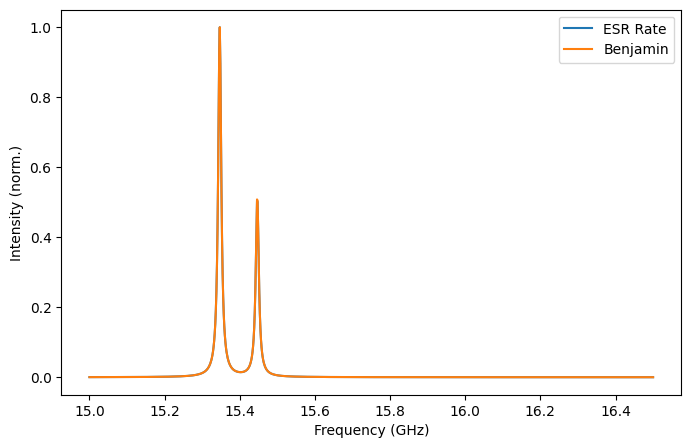

In [7]:
# Compare the two ESR Simulatiions
f_B, Signal_B = ESR.calcESR_FreqSweep_Benjamin(spinsys, FreqRange=[15, 16.5], N=1000, AllowPumping=True, norm=True,lw=0.01)
f_A, Signal_A = ESR.calcESR_FreqSweep_ESRrate(spinsys, FreqRange=[15, 16.5], N=1000, norm=True)

plt.figure(figsize=(8, 5))
plt.plot(f_A, Signal_A, label='ESR Rate')
plt.plot(f_B, Signal_B, label='Benjamin')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Intensity (norm.)')
plt.legend()
plt.show()

# Tipfieldsweep

In [9]:
vis.plotESR_Tipfieldsweep(spinsys,N_Freq=1000,N_B=200,BTipRange=[-0.02,0.02],FreqRange=[12,17]);